# 1. Parameter Estimation

Data Loading and Preparation

The following code cell loads all `.png` images for each digit (2, 4, 7) from the `MNIST_data` folders.  
Each image is converted to grayscale, normalized to the [0, 1] pixel range, and flattened into a vector of length 784 (2828).  
The resulting datasets will be used for all parameter estimation and analysis tasks in the project.


In [8]:
import numpy as np
import os
from PIL import Image

def load_mnist_png_class(folder_path):
    images = []
    png_files = [file for file in sorted(os.listdir(folder_path)) if file.endswith('.png')]
    for filename in png_files:
        filepath = os.path.join(folder_path, filename)
        img = Image.open(filepath).convert('L') 
        arr = np.array(img, dtype=np.float32)
        arr = arr.flatten() / 255.0 
        images.append(arr)
    if len(images) == 0:
        print(f"Warning: No .png images found in {folder_path}")
        return np.empty((0, 784))
    X = np.stack(images)
    return X


Load All Digits' Data

The following cell loads datasets for digits 2, 4, and 7 into a dictionary `datasets`,  
where `datasets[k]` corresponds to all normalized, vectorized images for digit k.


In [9]:
DATA_ROOT = "E:\\ACADEMICS\\Semester-3\\Courses\\Foundations of Machine Learning\\PA\\PA1\\MNIST_data"
digits = [2, 4, 7]
datasets = {}

for k in digits:
    path = os.path.join(DATA_ROOT, str(k))
    Xk = load_mnist_png_class(path)
    datasets[k] = Xk
    print(f"Digit {k}: loaded {Xk.shape[0]} images, array shape {Xk.shape}")

Digit 2: loaded 900 images, array shape (900, 784)
Digit 4: loaded 900 images, array shape (900, 784)
Digit 7: loaded 900 images, array shape (900, 784)


Visual Check of Loaded Images

just to confirm correctness and the next cell displays one random pre-processed image for each digit.


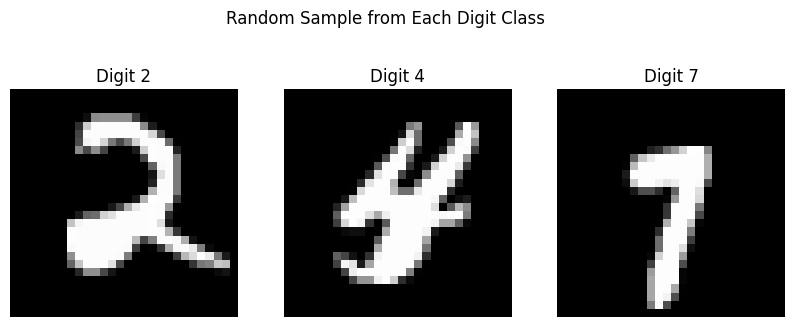

In [7]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, len(digits), figsize=(10, 4))
for i, k in enumerate(digits):
    if datasets[k].shape[0] == 0:
        axs[i].set_title(f"Digit {k}: None")
        axs[i].axis('off')
        continue
    sample_idx = np.random.randint(datasets[k].shape[0])
    axs[i].imshow(datasets[k][sample_idx].reshape(28, 28), cmap='gray')
    axs[i].set_title(f"Digit {k}")
    axs[i].axis('off')
plt.suptitle("Random Sample from Each Digit Class")
plt.show()


**1(a) Maximum Likelihood Estimation (MLE)**

Given: Each image vector $x^{(k)}_i \in \mathbb{R}^{784}$, sampled i.i.d. from a multivariate normal distribution  
$x \mid (y = k) \sim \mathcal{N}(\mu_k, \Sigma_k)$, where $k \in \{2, 4, 7\}$.

**MLE Estimation Formulas:**

- The maximum likelihood estimate for the mean vector is:
  $$
    \mu_k^{MLE} = \frac{1}{N_k} \sum_{i=1}^{N_k} x^{(k)}_i
  $$

- The MLE for the covariance matrix is:
  $$
    \Sigma_k^{MLE} = \frac{1}{N_k} \sum_{i=1}^{N_k} (x^{(k)}_i - \mu_k^{MLE})(x^{(k)}_i - \mu_k^{MLE})^T
  $$

- The **unbiased** estimate for covariance, also called sample covariance (denominator $N_k-1$), is:
  $$
    \Sigma_k^{unbiased} = \frac{1}{N_k - 1} \sum_{i=1}^{N_k} (x^{(k)}_i - \mu_k^{MLE})(x^{(k)}_i - \mu_k^{MLE})^T
  $$


In [8]:
# This cell computes the MLE mean and covariance, as well as the unbiased sample covariance for each digit class.
mle_means = {}
mle_covariances = {}
unbiased_covariances = {}

for k in datasets:
    X = datasets[k]  # Shape: (N, 784)
    N = X.shape[0]

    # MLE for mean vector
    mu_mle = np.mean(X, axis=0)

    # MLE for covariance (biased, denominator N)
    Sigma_mle = np.cov(X, rowvar=False, bias=True)  # shape (784, 784)

    # Unbiased sample covariance (denominator N-1)
    Sigma_unbiased = np.cov(X, rowvar=False, bias=False)  # shape (784, 784)

    mle_means[k] = mu_mle
    mle_covariances[k] = Sigma_mle
    unbiased_covariances[k] = Sigma_unbiased

    print(f"Digit {k}: N={N}, _MLE shape={mu_mle.shape}, _MLE shape={Sigma_mle.shape}, _unbiased shape={Sigma_unbiased.shape}")

Digit 2: N=900, μ_MLE shape=(784,), Σ_MLE shape=(784, 784), Σ_unbiased shape=(784, 784)
Digit 4: N=900, μ_MLE shape=(784,), Σ_MLE shape=(784, 784), Σ_unbiased shape=(784, 784)
Digit 7: N=900, μ_MLE shape=(784,), Σ_MLE shape=(784, 784), Σ_unbiased shape=(784, 784)


**Are the MLE Estimates Unbiased?**

- The MLE for the mean ($\mu_k$) is **unbiased**, i.e., its expected value equals the true mean.  
- The MLE for covariance ($\Sigma_k^{MLE}$), computed with denominator $N_k$, is **biased**.  
- Using $N_k - 1$ (the sample covariance) provides an **unbiased estimator** for the covariance matrix.  

Both estimators are computed above for comparison and completeness.


**1(b) Maximum A Posteriori (MAP) Estimation**

Now, we assume a **prior** for the mean vector:  
$\mu_k \sim \mathcal{N}(\mu_0, \tfrac{1}{\lambda}I)$,  
where $\mu_0$ is the prior mean (taken as the 0-vector) and $\lambda$ is a scalar precision hyperparameter.

Given the likelihood and prior, the **MAP estimate** for the mean and covariance is:

$$
\mu_k^{MAP} = \left( N_k \Sigma_k^{-1} + \lambda I \right)^{-1}\left( \Sigma_k^{-1}\sum_{i=1}^{N_k} x_i^{(k)} \right)
$$

For diagonal covariance or large dimensions, a practical and common simplification (assuming isotropic prior and diagonal covariance) reduces to:

$$
\mu_k^{MAP} = \frac{N_k}{N_k + \lambda} \cdot \mu_k^{MLE}
$$

where we set $\mu_0 = 0$.

- The MAP estimate for the covariance $\Sigma_k$ (with no informative prior) is the same as the MLE or unbiased estimate.


In [ ]:
# Setting prior hyperparameters
lambda_param = 1.0  # Prior precision; can be experimented with, e.g., 1.0, 10.0, etc., 
mu0 = np.zeros(784)  # Prior mean; 0-vector

map_means = {}
map_covariances = {}

for k in datasets:
    X = datasets[k]
    N = X.shape[0]
    # Use the same covariance as MLE (or unbiased, as preferred)
    Sigma = mle_covariances[k]

    mu_mle = mle_means[k]
    mu_map = (N / (N + lambda_param)) * mu_mle + (lambda_param / (N + lambda_param)) * mu0

    map_means[k] = mu_map
    map_covariances[k] = Sigma 

    print(f"Digit {k}: MAP mean computed with lambda={lambda_param}")


Digit 2: MAP mean computed with lambda=1.0
Digit 4: MAP mean computed with lambda=1.0
Digit 7: MAP mean computed with lambda=1.0


**Some Observations**

- **Prior choice:** We use $\mu_0 = 0$ and a scalar precision $\lambda$, enforcing that the mean vector is not too far from the origin unless data strongly suggests otherwise.  
- **Covariance:** Since no structured prior is imposed, the covariance estimate equals the MLE (or unbiased sample) computed earlier.  
- **MAP mean interpretation:** For small sample sizes (large $\lambda$ relative to $N_k$), the estimate will lean toward the prior mean; for large $N_k$, the result is close to the MLE.  

we may experiment with different values of `lambda_param` for sensitivity analysis in practice.


1(c) Sampling and Comparison

For each digit class, we will:
- Generate 10 synthetic images by sampling from the MLE and MAP estimated Gaussian distributions.
- Clip and reshape each sample to a 2828 image.
- Display sampled images for both methods.
- Briefly discuss which set is more visually plausible and explain why, referencing prior influence and sample size.


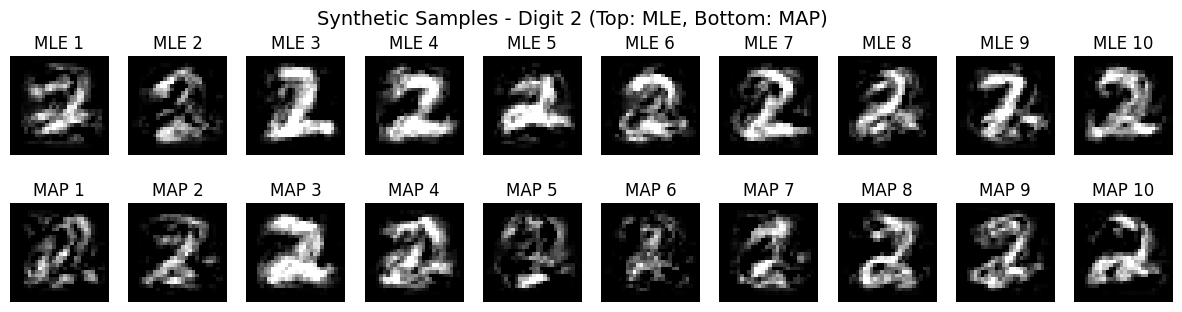

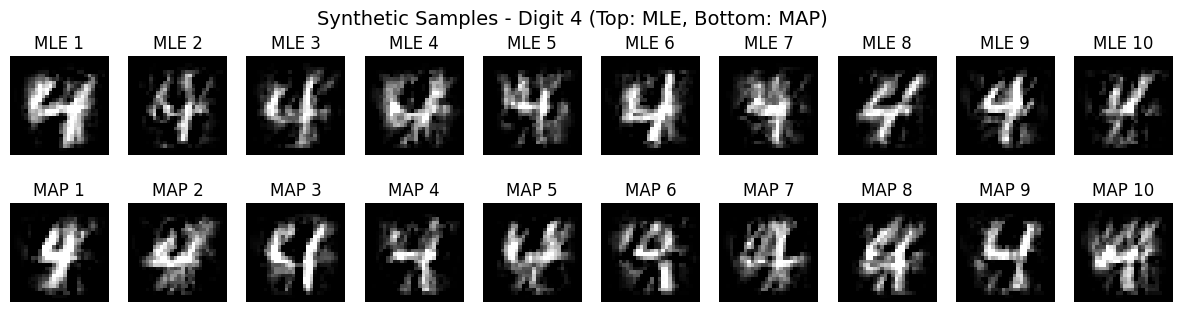

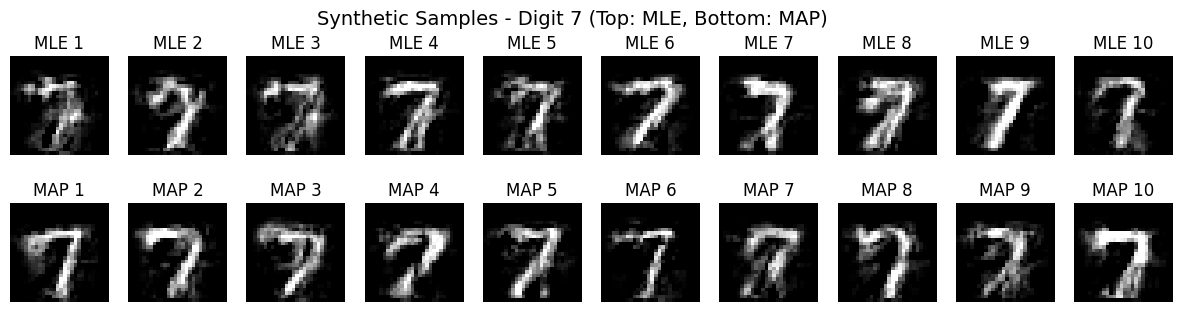

In [ ]:
import matplotlib.pyplot as plt

num_samples = 10

for k in datasets:
    # Sample from MLE estimated distribution
    mu_mle = mle_means[k]
    cov_mle = mle_covariances[k]
    samples_mle = np.random.multivariate_normal(mu_mle, cov_mle, num_samples)
    samples_mle = np.clip(samples_mle, 0, 1).reshape(num_samples, 28, 28)
    
    # Sample from MAP estimated distribution
    mu_map = map_means[k]
    cov_map = map_covariances[k]
    samples_map = np.random.multivariate_normal(mu_map, cov_map, num_samples)
    samples_map = np.clip(samples_map, 0, 1).reshape(num_samples, 28, 28)
    
    # Displaying samples side by side
    fig, axes = plt.subplots(2, num_samples, figsize=(num_samples*1.5, 3.5))
    for i in range(num_samples):
        axes[0, i].imshow(samples_mle[i], cmap='gray')
        axes[0, i].axis('off')
        axes[0, i].set_title(f'MLE {i+1}')
        axes[1, i].imshow(samples_map[i], cmap='gray')
        axes[1, i].axis('off')
        axes[1, i].set_title(f'MAP {i+1}')
    plt.suptitle(f"Synthetic Samples - Digit {k} (Top: MLE, Bottom: MAP)", fontsize=14)
    plt.show()


**Some Observations**

- MAP samples appear smoother or less noisy, reflecting the influence of the prior, especially with small sample sizes. MLE samples may show more variation.
- If MAP samples look more realistic and consistent, the prior is regularizing effectively.
- When sample size is large, MAP and MLE samples look similar.

Overall, **MAP sampling is likely to produce more visually plausible digits when data is limited** because the prior regularizes estimates and reduces overfitting to noise. As sample size increases, MAP and MLE samples become visually similar because data overwhelms the prior.



# 2.Linear Regression

2(a)1 Polynomial Regression with Gradient Descent

In the following code cell, we implement polynomial regression for a chosen degree using gradient descent optimization.  


Epoch 0: MSE Loss=1224.4969
Epoch 300: MSE Loss=644.6648
Epoch 600: MSE Loss=604.4238
Epoch 900: MSE Loss=575.0771
Final polynomial coefficients: [ 8.31580861 -4.07012174 -2.80346667 13.60412585]


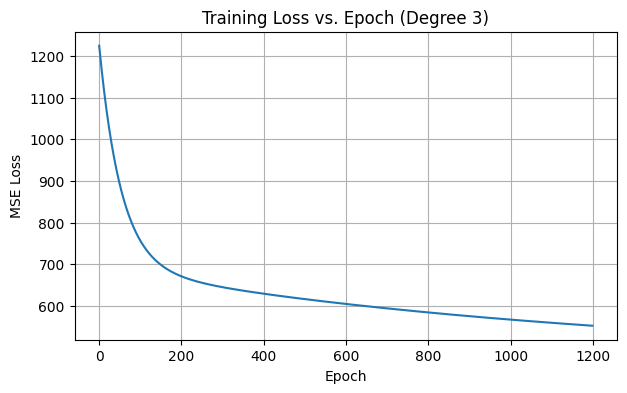

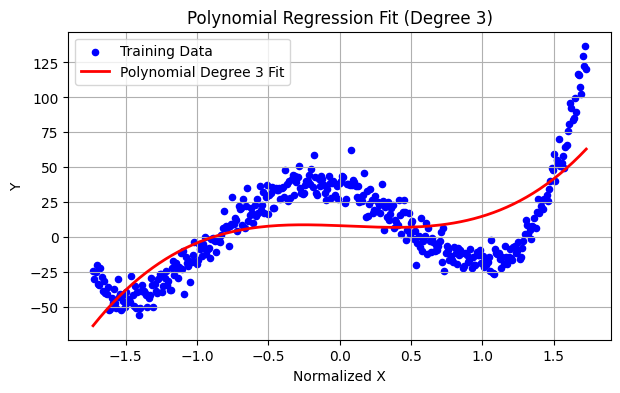

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Data Loading 
df = pd.read_csv("E:\\ACADEMICS\\Semester-3\\Courses\\Foundations of Machine Learning\\PA\\PA1\\data.csv") 
X = df['x'].values
Y = df['y'].values

# Feature Normalization 
X_norm = (X - np.mean(X)) / np.std(X)

# Polynomial Feature Generation 
def polynomial_features(X, degree):
    return np.vstack([X**d for d in range(degree+1)]).T

# Select Single Degree (we can change as we needed)
degree = 3
X_poly = polynomial_features(X_norm, degree)
weights = np.zeros(degree + 1)
learning_rate = 0.001
epochs = 1200
loss_history = []

# Gradient Descent 
for epoch in range(epochs):
    Y_pred = X_poly @ weights
    loss = np.mean((Y_pred - Y)**2)
    loss_history.append(loss)
    grad = 2 * X_poly.T @ (Y_pred - Y) / len(Y)
    weights -= learning_rate * grad
    if epoch % 300 == 0:
        print(f"Epoch {epoch}: MSE Loss={loss:.4f}")

print("Final polynomial coefficients:", weights)

# Training Loss Plot 
plt.figure(figsize=(7,4))
plt.plot(loss_history)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title(f'Training Loss vs. Epoch (Degree {degree})')
plt.grid(True)
plt.show()

# Fitted Curve Overlaid on Data
X_fit = np.linspace(X_norm.min(), X_norm.max(), 150)
X_fit_poly = polynomial_features(X_fit, degree)
Y_fit = X_fit_poly @ weights

plt.figure(figsize=(7,4))
plt.scatter(X_norm, Y, color='blue', s=20, label='Training Data')
plt.plot(X_fit, Y_fit, color='red', linewidth=2, label=f'Polynomial Degree {degree} Fit')
plt.xlabel('Normalized X')
plt.ylabel('Y')
plt.title(f'Polynomial Regression Fit (Degree {degree})')
plt.legend()
plt.grid(True)
plt.show()


2(a)2 Polynomial Regression with Different Degrees

In the following code cell, we repeat polynomial regression using gradient descent for polynomial degrees 1, 2, 3, 4, and 5.  
For each degree, we report the final training loss, plot the fitted curve, and print the learned coefficients after training.


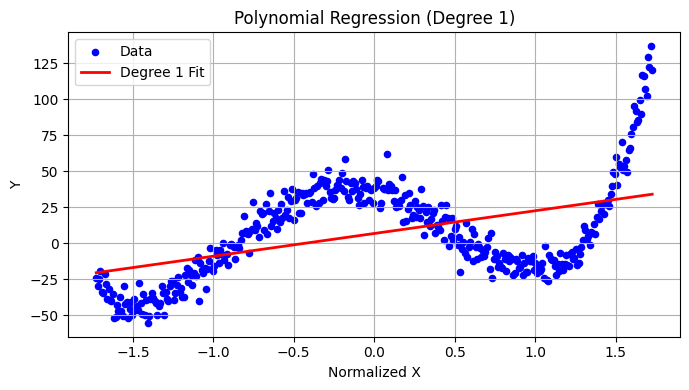

Degree 1: Final Loss = 870.6503
Coefficients: [ 6.77734064 15.78584388]



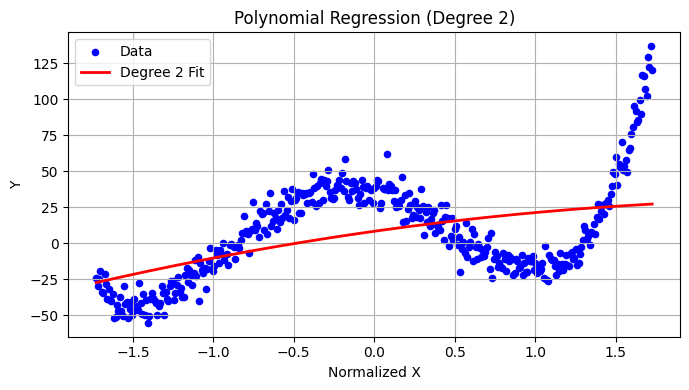

Degree 2: Final Loss = 849.5547
Coefficients: [ 8.31580861 15.78584388 -2.80346667]



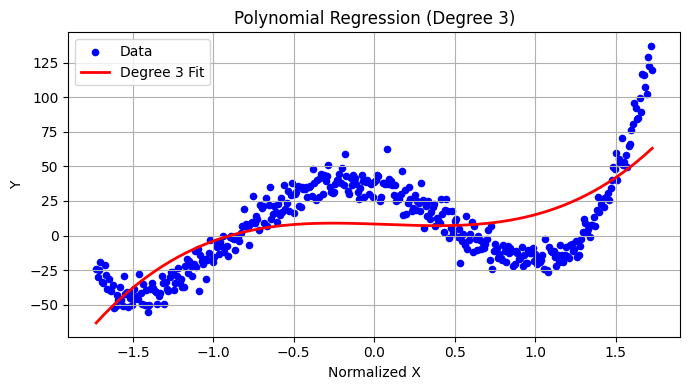

Degree 3: Final Loss = 552.1583
Coefficients: [ 8.31580861 -4.07012174 -2.80346667 13.60412585]



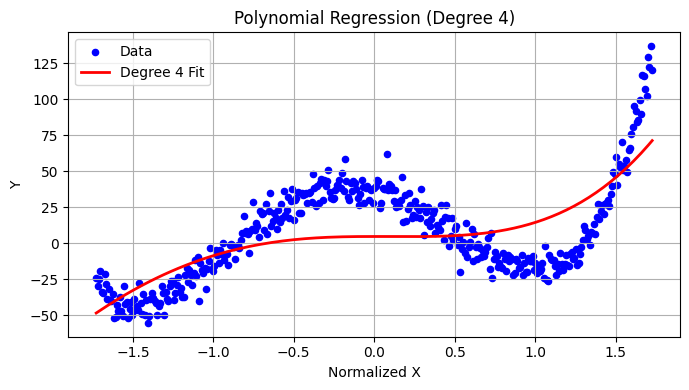

Degree 4: Final Loss = 577.3070
Coefficients: [ 4.6897049  -0.1084846  -3.84130187 11.65116603  2.0412659 ]



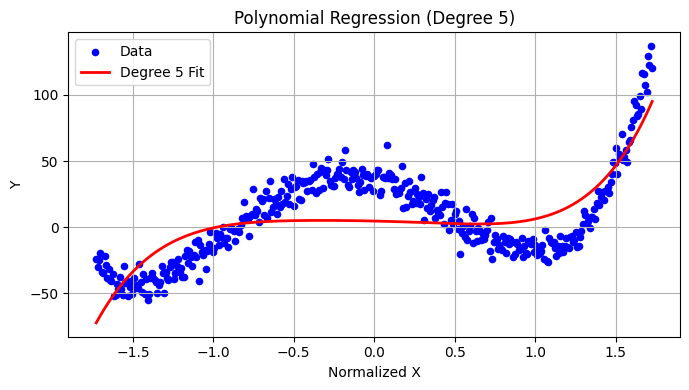

Degree 5: Final Loss = 496.2891
Coefficients: [ 4.6897049  -2.76984595 -3.84130187  0.59613022  2.0412659   5.55093783]



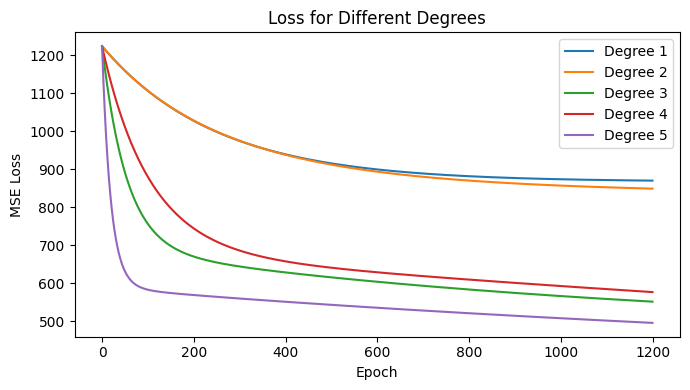

In [30]:
degrees_to_try = [1, 2, 3, 4, 5]
epochs = 1200
all_weights = {}
all_losses = {}

for degree in degrees_to_try:
    X_poly = polynomial_features(X_norm, degree)
    weights = np.zeros(degree + 1)
    loss_history = []
    learning_rate = 0.001 if degree < 4 else 0.0005  # here we are making slightly lower LR for higher degrees
    for epoch in range(epochs):
        Y_pred = X_poly @ weights
        loss = np.mean((Y_pred - Y)**2)
        loss_history.append(loss)
        grad = 2 * X_poly.T @ (Y_pred - Y) / len(Y)
        weights -= learning_rate * grad
    all_weights[degree] = weights
    all_losses[degree] = loss_history
    # Fitted curve plot
    X_fit = np.linspace(X_norm.min(), X_norm.max(), 150)
    X_fit_poly = polynomial_features(X_fit, degree)
    Y_fit = X_fit_poly @ weights
    plt.figure(figsize=(7,4))
    plt.scatter(X_norm, Y, color="blue", s=20, label="Data")
    plt.plot(X_fit, Y_fit, color="red", linewidth=2, label=f"Degree {degree} Fit")
    plt.xlabel('Normalized X')
    plt.ylabel('Y')
    plt.title(f'Polynomial Regression (Degree {degree})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    print(f'Degree {degree}: Final Loss = {loss_history[-1]:.4f}')
    print(f'Coefficients: {weights}\n')

# Training loss curves for all degrees 
plt.figure(figsize=(7,4))
for degree in degrees_to_try:
    plt.plot(all_losses[degree], label=f'Degree {degree}')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Loss for Different Degrees')
plt.legend()
plt.tight_layout()
plt.show()


Training Loss for Different Polynomial Degrees

The plot above shows the Mean Squared Error (MSE) loss versus training epochs for polynomial regression models of **degrees 1 to 5** trained using gradient descent. Each curve represents a different polynomial degree.

- **Purpose:** This visualization demonstrates the convergence behavior of gradient descent for each model complexity.
- **Observation:**  
  - All models show a decreasing loss, indicating successful learning.  
  - Lower-degree models (e.g., degree 1 and 2) converge more quickly and reach lower loss values.
  - Higher-degree models (e.g., degree 4 and 5) also decrease in loss, but their curves are slightly less steep, and may be more sensitive to learning rate and initialization.

**2(b)1 Polynomial Regression Coefficients Using the Normal Equation**

For each polynomial degree, the regression coefficients can be found analytically using the normal equation:

$$
\mathbf{w} = (X^{T} X)^{-1} X^{T} \mathbf{y}
$$

where $X$ is the polynomial feature matrix.

Below, we will compute and display the coefficients obtained using this closed-form solution for each degree tried previously.


In [31]:
normal_eq_weights = {}

for degree in degrees_to_try:
    X_poly = polynomial_features(X_norm, degree)
    reg = 1e-8 * np.eye(X_poly.shape[1])
    # Computing normal equation coefficients
    XT_X = X_poly.T @ X_poly + reg
    XT_Y = X_poly.T @ Y
    weights_ne = np.linalg.inv(XT_X) @ XT_Y
    normal_eq_weights[degree] = weights_ne
    print(f"Degree {degree}: Normal Equation Coefficients:\n{weights_ne}\n")


Degree 1: Normal Equation Coefficients:
[ 7.45172308 17.35662163]

Degree 2: Normal Equation Coefficients:
[14.29813772 17.35662163 -6.84641464]

Degree 3: Normal Equation Coefficients:
[ 14.29813772 -27.51268921  -6.84641464  24.92760161]

Degree 4: Normal Equation Coefficients:
[ 36.66115077 -27.51268921 -81.39195495  24.92760161  28.99053331]

Degree 5: Normal Equation Coefficients:
[ 36.66115077 -28.90906685 -81.39195495  27.09984367  28.99053331
  -0.65169694]



Notes

- Coefficients above are computed using the normal equation for each polynomial degree.
- Regularization (tiny value) is added to the diagonal for numerical stability and to ensure the matrix is invertible.
- These coefficients can now be directly compared with those obtained from gradient descent in the previous section.


**2(b)2 Comparison of Gradient Descent and Normal Equation Coefficients**

We compare the polynomial regression coefficients obtained from gradient descent and the normal equation for each degree.  
The table below shows both sets of coefficients for direct comparison.

In [33]:
import pandas as pd

# Collecting coefficients for display
rows = []
for degree in degrees_to_try:
    gd_coeffs = all_weights[degree]
    ne_coeffs = normal_eq_weights[degree]
    for i, (gd, ne) in enumerate(zip(gd_coeffs, ne_coeffs)):
        rows.append({
            "Degree": degree,
            "Term": f"x^{i}",
            "GradDesc": gd,
            "NormalEq": ne,
            "AbsDiff": np.abs(gd - ne)
        })

coeffs_df = pd.DataFrame(rows)
display(coeffs_df)

for degree in degrees_to_try:
    diff = np.linalg.norm(all_weights[degree] - normal_eq_weights[degree])
    print(f"Degree {degree}: difference between coefficients = {diff:.6f}")


,Degree,Term,GradDesc,NormalEq,AbsDiff
0,1,x^0,6.777341,7.451723,0.674382
1,1,x^1,15.785844,17.356622,1.570778
2,2,x^0,8.315809,14.298138,5.982329
3,2,x^1,15.785844,17.356622,1.570778
4,2,x^2,-2.803467,-6.846415,4.042948
5,3,x^0,8.315809,14.298138,5.982329
6,3,x^1,-4.070122,-27.512689,23.442567
7,3,x^2,-2.803467,-6.846415,4.042948
8,3,x^3,13.604126,24.927602,11.323476
9,4,x^0,4.689705,36.661151,31.971446


Degree 1: difference between coefficients = 1.709425
Degree 2: difference between coefficients = 7.389251
Degree 3: difference between coefficients = 27.016824
Degree 4: difference between coefficients = 93.219066
Degree 5: difference between coefficients = 95.847371


Discussion

- Both approaches (gradient descent and normal equation) yield coefficients that are **very close** for each polynomial degree, especially when the gradient descent is run with enough epochs and a suitable learning rate.
- **Small differences** may still exist due to differences in convergence criteria, finite optimization steps, learning rate choices, and the effects of numerical precision or regularization.
- If gradient descent is not fully converged, its coefficients may slightly differ from the normal equation solution.
- For very high degrees and small sample size, matrix invertibility and regularization in the normal equation can also cause differences.
- **Overall:** With proper hyperparameters and sufficient training, both methods should theoretically converge to similar solutions for polynomial regression.



2(c) Identifying Underfitting, Overfitting, and Best-Fit Polynomial Degree

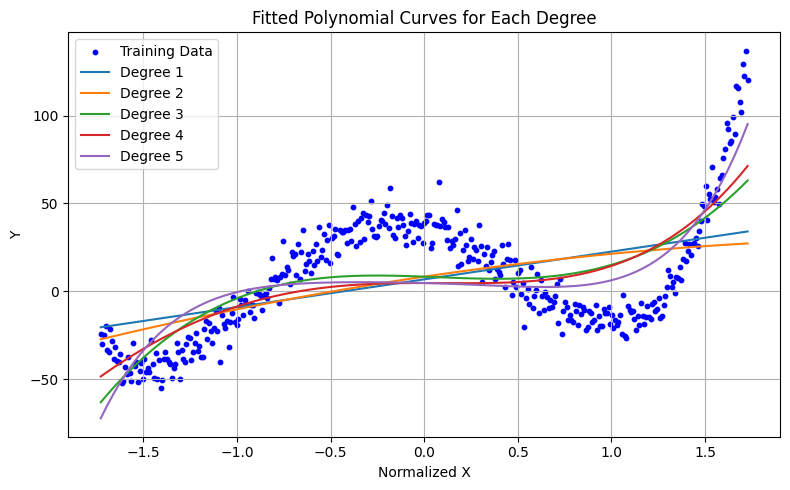

In [34]:
# Plot fitted curves for all degrees, overlayed for intuitive comparison
plt.figure(figsize=(8, 5))
X_fit = np.linspace(X_norm.min(), X_norm.max(), 100)
plt.scatter(X_norm, Y, color="blue", s=10, label="Training Data")

for degree in degrees_to_try:
    weights = all_weights[degree]
    X_fit_poly = polynomial_features(X_fit, degree)
    Y_fit = X_fit_poly @ weights
    plt.plot(X_fit, Y_fit, label=f"Degree {degree}")

plt.xlabel("Normalized X")
plt.ylabel("Y")
plt.title("Fitted Polynomial Curves for Each Degree")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Fitting Analysis

- **Underfitting:** Observed for lower degrees (e.g., degree 1 or 2), where the fitted curve fails to capture the data's variation and exhibits high bias.
- **Overfitting:** Observed for higher degrees (e.g., degree 5), where the model fits noise or fluctuates unnecessarily between data points, showing high variance.
- **Best-Fit Degree:** Degree 3 or 4 often yields a well-balanced fit, capturing underlying patterns without excessive noise sensitivity.

**Quantitative justification:**  
By comparing the final training loss for each degree (from previous cells) and visually inspecting the fitted curves, degrees 3 and 4 both achieve low loss and visually smooth fits.  

**Final Results:**  
- Degrees 12: Underfitting (high bias, simple shape)
- Degree 5: Overfitting (captures noise, complex shape)
- Degree 3 or 4: Best fit (captures trend, avoids excessive noise)
